In [1]:
import pandas as pd
import numpy as np
import xarray as xr
import scipy
import glob
import pathlib
import matplotlib.pyplot as plt
import matplotlib as mpl
import string
letters = string.ascii_lowercase
import helpers
import plot_helpers

extra_figs = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_resubmission/figures/paper_supporting')
extra_figs.mkdir(parents=1, exist_ok=1)

CMAP = mpl.colors.ListedColormap(plt.get_cmap('Reds')(np.linspace(.25,1,265)))
dpi = 300
ext = 'pdf'

c1, c2 = 'b', 'g'

#### IWP DISTRIBUTION

This study assessed a series of IWP thresholds, here we review the distribution of anvil IWP in the deep convective clouds.

In [2]:
# load data

datadir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_resubmission/data/statistics_IWP')
ds_flist = sorted(list(datadir.glob('*.nc')))
li = []
for i in range(len(ds_flist)):
    ds = xr.open_dataset(ds_flist[i])
    li.append(ds)
ds_iwp = xr.concat(li, dim='system')

In [3]:
# estimate percentiles from histogram

nbins = np.linspace(1e-3, 1e2, 200)
lbins = np.logspace(np.log10(1e-3), np.log10(1e2), 100)

percentiles = np.arange(0, 1.0, 0.05)
pi_values = pd.DataFrame(index=percentiles)

var = "anvil_fwp_lhist"
counts = ds_iwp[var].sum("system")
edges = np.log10(lbins)

cdf = counts.cumsum().values
cdf = cdf / cdf[-1]

pi_values[var] = np.interp(
    percentiles,
    cdf,
    edges[1:],
)
if not counts.dims[0] == "nbins":
    pi_values[var] = 10**pi_values[var]

pi_values.index.name = "percentile"
pi_values.index = pi_values.index.round(2)
pi_values = pi_values.loc[:,var]

# pi_values.to_csv('/home/b/b382635/s/my_notebooks/model_paper/grl_resubmission/scripts/iwp_percentiles.csv')

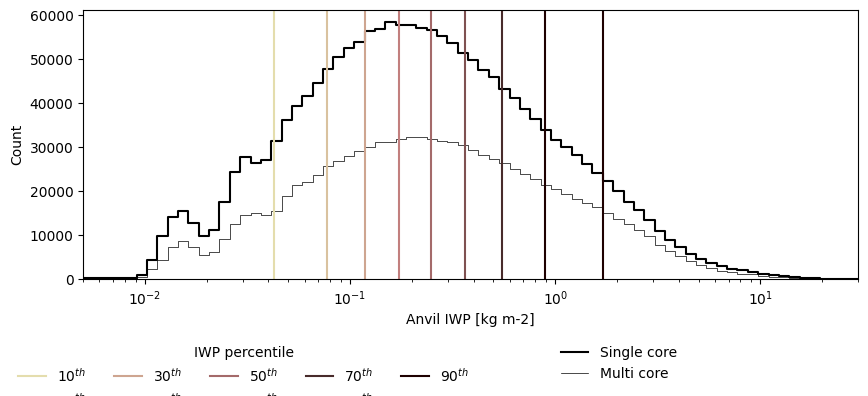

In [28]:
# view

fig, ax = plt.subplots(figsize=(10,3.5))

# d = ds_iwp.anvil_fwp_lhist.dropna('system')
# y = (d.sum("system"))# / d.system.size)
# y.plot.step(ax=ax, c='k', )

d = ds_iwp.where(ds_iwp.ncores==1).anvil_fwp_lhist.dropna('system')
y = (d.sum("system") )#/ d.system.size)
y.plot.step(ax=ax, c='k', lw=1.5)
# ax.fill_between(y.coords[y.dims[0]], y, step='pre', color=c1, alpha=.15)

d = ds_iwp.where(ds_iwp.ncores>1).anvil_fwp_lhist.dropna('system')
y = (d.sum("system"))# / d.system.size)
y.plot.step(ax=ax, c='k', lw=.5)
# ax.fill_between(y.coords[y.dims[0]], y, step='pre', color=c2, alpha=.15)

ax.set_xlabel('Anvil IWP [kg m-2]')
ax.set_ylabel('Count')
ax.set_xscale('log')
# ax.grid()

cmap = mpl.colors.ListedColormap(plt.get_cmap('pink_r')(np.linspace(.2,1.256)))
for pi in pi_values.index[2::2]:
    ax.axvline(pi_values[pi], c=cmap(pi), label=f"{pi:.2}")
# ax.axvline(0.2, ls=':', c='k', lw=2, label="Sokol '24 & Gasparini '19")
ax.set_xlim(5e-3,3e1)
ax.set_ylim(0,None)

# legends

l1_handles = [mpl.lines.Line2D([], [], color=cmap(pi), label=f"{pi*100:.0f}"+"$^{th}$") for pi in pi_values.index[2::2]]
l1 = ax.legend(handles=l1_handles, title="IWP percentile", loc='upper left', bbox_to_anchor=(-.1, -.2), ncol=5, frameon=0)
ax.add_artist(l1)

l2_handles = [
    # mpl.lines.Line2D([], [], color='k', lw=2, label='All DCCs'),
    mpl.lines.Line2D([], [], color='k', lw=1.5, label='Single core'),
    mpl.lines.Line2D([], [], color='k', lw=.5, label='Multi core'),
    # mpl.lines.Line2D([], [], color='k', ls=':', lw=2, label="Sokol '24 & Gasparini '19"),
]
l2 = ax.legend(handles=l2_handles, loc='upper left', bbox_to_anchor=(.6, -.2), frameon=0)

fig.savefig(extra_figs / f'iwp_distribution.{ext}', bbox_inches='tight', dpi=dpi, bbox_extra_artists=[l1, l2],)

#### LOAD MORE DATA

In [5]:
# load
datadir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_resubmission/data/statistics_L2')
ds_flist = sorted(list(datadir.glob('*.nc')))
li = []
for i in range(len(ds_flist)):
    ds = xr.open_dataset(ds_flist[i])
    li.append(ds)
ds_all = xr.concat(li, dim='system')

# filter
gsystems = ds_all.max_CMF.dropna('system').system
ds_good = ds_all.sel(system=gsystems)
ds = ds_good.where(ds_good.lifestages_valid).dropna('system', how='all')

In [6]:
df_metrics = helpers.dccs_by_intensity_metrics(ds, ds[['total_CMT',]])

#### LIFESTAGE DURATION
Assess the typical durations of each cloud lifestage

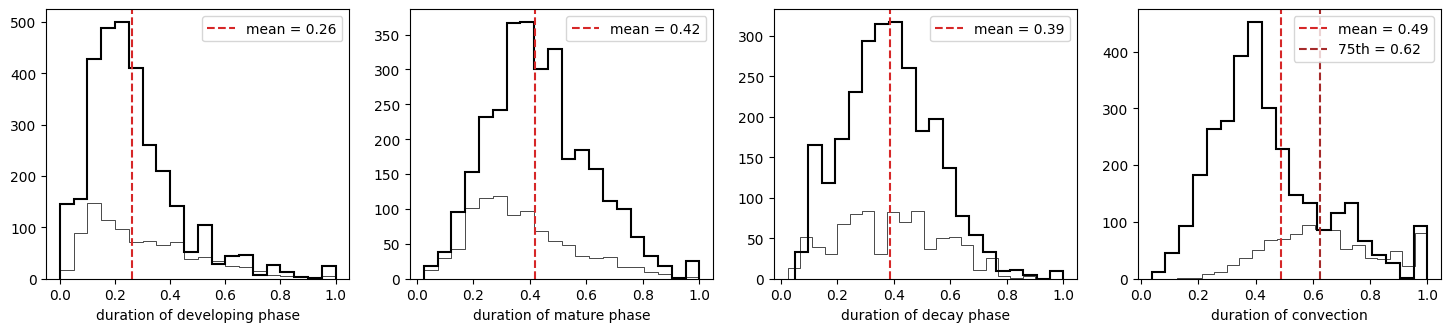

In [27]:
fig, axs = plt.subplots(1,4, figsize=(18, 3.5))

params = dict(ec="k", fc='none', bins=20, histtype='step', )

plots = [
    (ds.t_max_depth, "duration of developing phase"),
    ((ds.t_max_area - ds.t_max_depth).where(lambda x: x > 0), "duration of mature phase"),
    ((1 - ds.t_max_area).where(lambda x: x > 0), "duration of decay phase"),
    (ds.conv_lifetime / ds.lifetime, "duration of convection"),
]

for ax, (d, xlabel) in zip(axs, plots):
    d.where(ds.ncores==1).plot.hist(ax=ax, lw=1.5, **params)
    d.where(ds.ncores>1).plot.hist(ax=ax, lw=.5, **params)

    mean = d.mean()
    median = d.median()

    ax.axvline(mean, c="tab:red", ls="--", label=f"mean = {mean.item():.2f}", lw=1.5)
    # ax.axvline(median, c="tab:blue", ls="--", label=f"median = {median.item():.2f}")

    if xlabel=="duration of convection":
        ax.axvline(d.quantile(.75), c="brown", ls="--", lw=1.5, label=f"75th = {d.quantile(.75).item():.2f}")

    ax.set_xlabel(xlabel)
    ax.legend()
    # ax.grid()

fig.savefig(extra_figs / f'lifestage_durations.{ext}', bbox_inches='tight', dpi=dpi)

#### CMF DISTRIBUTION
This study assessed CMF quantiles, here we reveiw the distribution of cloud CMF

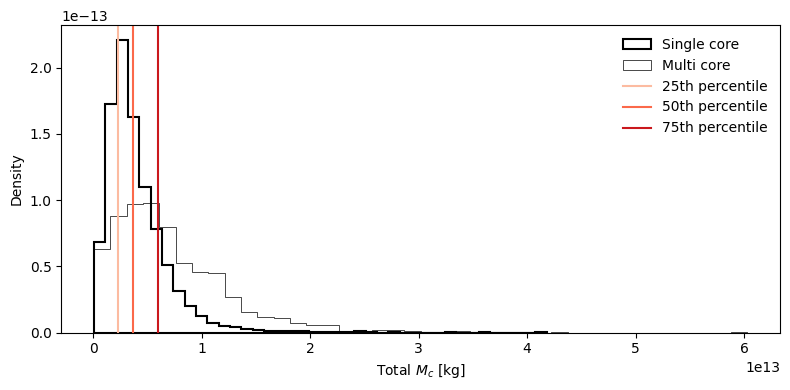

In [30]:
# data

fig, ax = plt.subplots(figsize=(8,4), layout="tight")
hist_params = dict(bins=40, density=True, histtype="stepfilled", alpha=1, fc="none", )

# histograms
# ds.total_CMT.plot.hist(ax=ax, lw=2, ec='k', **hist_params, label='All DCCs')
ds.where(ds.ncores==1).total_CMT.plot.hist(ax=ax, lw=1.5, ec='k', **hist_params, label='Single core')
ds.where(ds.ncores>1).total_CMT.plot.hist(ax=ax, lw=.5, ec='k', **hist_params, label='Multi core')

# quantiles
quantiles = ds.total_CMT.quantile([0.25, 0.5, 0.75]).rename({"quantile":"pi"})

for i, q in enumerate(quantiles.pi.values):
    ax.axvline(
        quantiles.sel(pi=q),
        color=CMAP(i / len(quantiles)),
        lw=1.5,
        ls='-',
        label=f"{int(100 * q)}th percentile",
    )

ax.set_xlabel("Total $M_c$ [kg]")
ax.set_ylabel("Density")
ax.legend(frameon=False)
# ax.grid()

fig.savefig(extra_figs / f'total_Mc_quartiles.{ext}', bbox_inches='tight', dpi=dpi)

#### CLOUD RESPONSE OF RELATED VARIABLES
Assess the cloud response to total convective mass flux for two related variables, total anvil condensate and anvil horizontal divergence

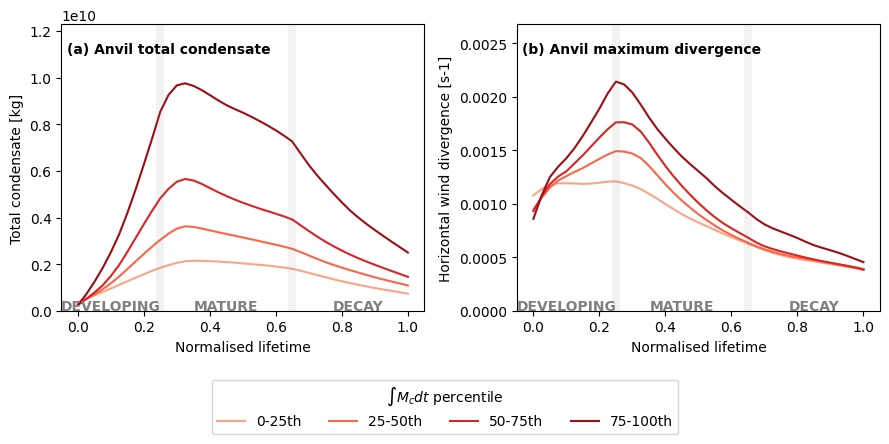

In [59]:
# data
cloud_variables = ["anvil_tw", "anvil_div_max"]

# mean evolution by percentile bin
pdata = helpers.group_dataset_by_intensity(ds[cloud_variables], df_metrics, apply=lambda x: x.mean("system", keep_attrs=True),)["total_CMT"]

# figure
N = len(cloud_variables)
fig, axs = plt.subplots(1,N, figsize=(N * 4.5, 3.75), layout="tight")
axs = np.atleast_1d(axs)

plot_titles = ["Anvil total condensate", "Anvil maximum divergence"]
plot_ylabels = ["Total condensate", "Horizontal wind divergence"]
legend_handles, legend_labels = None, None

for i, var in enumerate(cloud_variables):
    ax = axs[i]

    for j, b in enumerate(pdata.bins.values):
        color = CMAP(j / 4 + 0.1)
        evolution = plot_helpers.get_evolution(pdata[var].sel(bins=b))
        evolution.plot(ax=ax, c=color, label=f"{b}th", zorder=1, lw=1.5)

    plot_helpers.show_phases(ax, y=ax.get_ylim()[1] * 0.05)

    ax.text(
        0.015,
        0.9,
        f"({letters[i]}) {plot_titles[i]}",
        c="k",
        weight="bold",
        transform=ax.transAxes,
    )

    ax.set_xlabel("Normalised lifetime")
    ax.set_ylabel(f"{plot_ylabels[i]} [{ds[var].units}]")
    ax.set_title(None)

    ax.set_ylim(0, ax.get_ylim()[1] * 1.2)

    if legend_handles is None:
        legend_handles, legend_labels = ax.get_legend_handles_labels()

legend = fig.legend(
    legend_handles,
    legend_labels,
    title=r"$\int M_c dt$ percentile",
    loc="center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=4,
    frameon=True,
)

fig.savefig(extra_figs / f'cloud_response_water_and_wind.{ext}', bbox_inches='tight', dpi=dpi)

#### PROCESSES DRIVING CMF->A_max

An extension to figure 3, this result tests the relationship between different convective processes and A_max

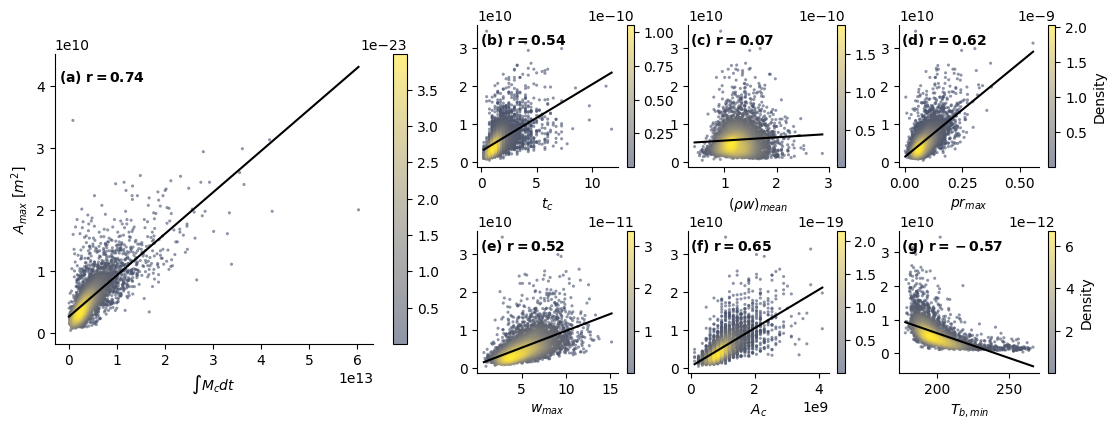

In [58]:
fs = 10
global_labels = {"total_CMT":r"$\int M_c dt\,$",
                 "total_CMT_l60":r"$\int M_c dt\,$",
                 "max_CMT":r"$M_{c,max}$",
                 "max_CMF":r"$(\rho w)_{max}$",
                 "mean_CMF":r"$(\rho w)_{mean}$",
                 "max_w":r"$w_{max}$",
                 "max_Ac":r"$A_c$",
                 "core_max_pr":r"$pr_{max}$",
                 "cloud_min_tt": r"$T_{b,min}$",
                 "conv_lifetime":r"$t_c$",
                 "Apred_v1":r'$\frac{1}{D\bar{\rho}}\int M_{c,max}\,dt$',
                 "Apred_v2":r'$\int \frac{M_c}{D\bar{\rho}}\,dt$',
                }

# metrics = ["total_CMT", "conv_lifetime", "mean_CMF", "max_w", "max_Ac", ]
metrics = ["total_CMT", "conv_lifetime", "mean_CMF", "core_max_pr", "max_w", "max_Ac", "cloud_min_tt" ]

di = {'all': [ds.ncores>0, dict(label=None, c='k')],
      'single': [ds.ncores==1, dict(label=None, c='k')],
      'multi': [ds.ncores>1, dict(label=None, c='grey')]}
hcmap = mpl.colors.ListedColormap(plt.get_cmap("cividis")(np.linspace(0.25, 1, 256)))

fig = plt.figure(figsize=(12,4))

grid = (2, 3)
nrows, ncols = grid
axs = [None] * (1 + nrows * ncols)

outer = mpl.gridspec.GridSpec(1, 2, figure=fig, wspace=0.05, width_ratios=[1, 1.5],
                              left=0.08, right=0.93, top=0.95, bottom=0.08)

left_gs = outer[0].subgridspec(3, 1, height_ratios=[.1, 1, .1], hspace=0)
axs[0] = fig.add_subplot(left_gs[1])
inner = outer[1].subgridspec(nrows, ncols, hspace=0.45, wspace=0.2)
for i in range(nrows * ncols):
    axs[i + 1] = fig.add_subplot(inner[i // ncols, i % ncols])

for i,ax in enumerate(axs):
    Y = ds["max_anvil_area"]
    ylab = "$A_{max}$ [$m^2$]"
        
    li = di['all']
    metric = metrics[i%len(metrics)]
    x = ds.where(li[0])[metric]
    y = Y.where(li[0])

    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    
    m, b, r, p, se = scipy.stats.linregress(x, y)
    x_fit = np.linspace(x.min(), x.max(), 200)
    label = rf"$\mathbf{{r={r:.2f}}}$" if p < 0.05 else rf"r={r:.2f}"
    ax.plot(x_fit, (m * x_fit + b), c=li[1]['c'], lw=1.5)

    xy = np.vstack([x, y])
    density = scipy.stats.gaussian_kde(xy)(xy)
    order = density.argsort()
    x_s, y_s, d_s = x[order], y[order], density[order]
    sc = ax.scatter(x_s, y_s, c=d_s, cmap=hcmap, s=5, alpha=0.6, rasterized=True, linewidths=0)
    if i in [3,6]:
        plt.colorbar(sc, ax=ax, label='Density')
    else:
        plt.colorbar(sc, ax=ax, )

    ax.set_xlabel(global_labels[metric], fontsize=fs)
    ax.spines[["top", "right"]].set_visible(False)

    letter = letters[i]
    ax.text(0.015, 0.95, rf"$\mathbf{{({letter})}}$ "+label, transform=ax.transAxes, fontsize=fs, va="top")

    if i in [0,len(metrics)]:
        ax.set_ylabel(ylab, fontsize=fs)

fig.savefig(extra_figs / f'relationships_to_Amax.{ext}', bbox_inches='tight', dpi=dpi)

#### SENSTIVITY TO ABH
The definition of the anvil base height is made using the profile of condensate of each particular DCC, here we assess the senstivity of results to that definition

In [ ]:
1. Does the position of the ABH make physical sense?

In [ ]:
2. Are the results senstive to edge cases in ABH?

In [ ]:
3. If you chose one consistent level to compare the different DCC, would the results change?

#### LAND/OCEAN
Here we explore whether the results of this study vary between land and ocean

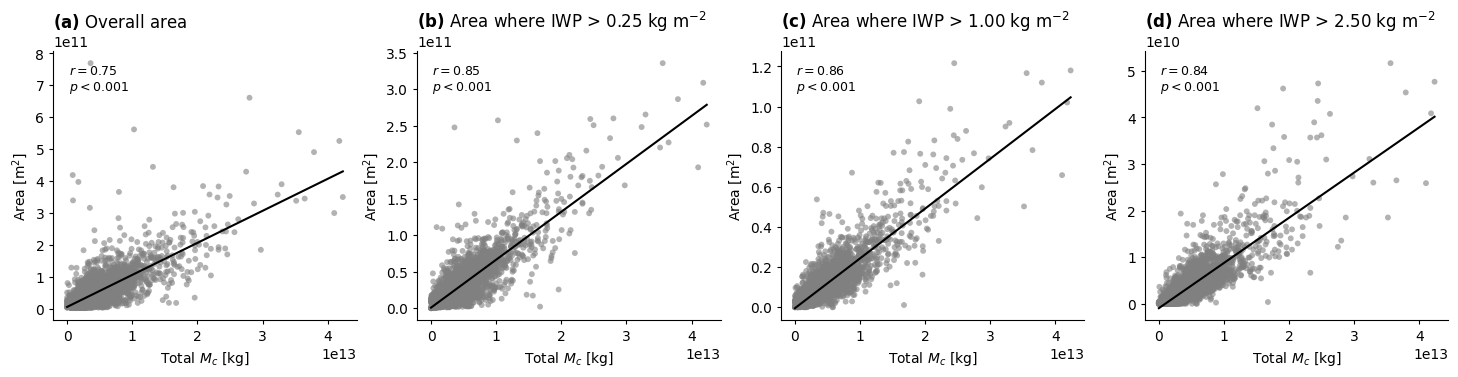

In [37]:
# OVERALL

fig, axs = plt.subplots(1,4, figsize=(18, 3.5))

params = dict()

x = ds.total_CMT
y_vars = [ds.total_cloud_area, ds.total_thick_area.sel(threshold=0.25), ds.total_thick_area.sel(threshold=1), ds.total_thick_area.sel(threshold=2.5), ]

for i, y in enumerate(y_vars):
    ax = axs[i]

    _, _, xline, yline, result = helpers.evaluate_predictions(x, y)
    ax.scatter(x, y, s=18, alpha=0.6, edgecolors="none", fc='grey')
    ax.plot(xline, yline, linewidth=1.5, c='k')
    p_text = r"$p < 0.001$" if result.pvalue < 0.001 else rf"$p = {result.pvalue:.3f}$"
    label = rf"$r = {result.rvalue:.2f}$" + "\n" + p_text #+ "\n" rf"slope = {result.slope:.2f}"
    ax.text(0.05, 0.95, label, transform=ax.transAxes, ha="left", va="top", fontsize=9)

    # axes
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=3, width=0.8)

    ax.set_xlabel("Total $M_c$ [kg]")
    ax.set_ylabel("Area [m$^2$]")

    title = (
        rf"$\mathbf{{({letters[i]})}}$ Overall area"
        if i == 0
        else rf"$\mathbf{{({letters[i]})}}$ Area where IWP > {y.threshold.values:.2f} kg m$^{{-2}}$"
    )
    ax.set_title(title, loc='left')

fig.savefig(extra_figs / 'figure02_scatter_plot.jpg', bbox_inches='tight', dpi=dpi)

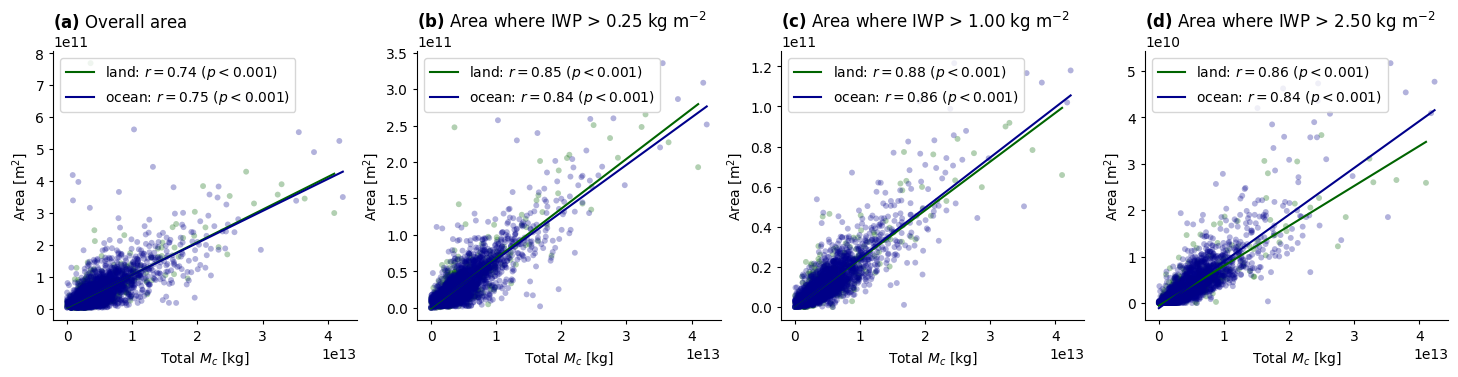

In [38]:
# LAND / OCEAN

fig, axs = plt.subplots(1,4, figsize=(18, 3.5))

params = dict()

x = ds.total_CMT
y_vars = [ds.total_cloud_area, ds.total_thick_area.sel(threshold=0.25), ds.total_thick_area.sel(threshold=1), ds.total_thick_area.sel(threshold=2.5), ]

colors = ['darkgreen', 'darkblue']
for i, y in enumerate(y_vars):
    ax = axs[i]

    for j, name in enumerate(('land','ocean')):
        is_ocean = ds.ocean_fraction
        _x, _y = x[is_ocean==j], y[is_ocean==j]

        _, _, xline, yline, result = helpers.evaluate_predictions(_x, _y)
        p_text = r"$p < 0.001$" if result.pvalue < 0.001 else rf"$p = {result.pvalue:.3f}$"
        label = rf"{name}: $r = {result.rvalue:.2f}$ ({p_text})"

        ax.scatter(_x, _y, s=18, alpha=0.3, edgecolors="none", fc=colors[j])
        ax.plot(xline, yline, linewidth=1.5, c=colors[j], label=label)
            
    # axes
    ax.legend(loc='upper left')
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=3, width=0.8)

    ax.set_xlabel("Total $M_c$ [kg]")
    ax.set_ylabel("Area [m$^2$]")

    title = (
        rf"$\mathbf{{({letters[i]})}}$ Overall area"
        if i == 0
        else rf"$\mathbf{{({letters[i]})}}$ Area where IWP > {y.threshold.values:.2f} kg m$^{{-2}}$"
    )
    ax.set_title(title, loc='left')

fig.savefig(extra_figs / 'figure02_land_vs_ocean.jpg', bbox_inches='tight', dpi=dpi)

ValueError: Inputs must not be empty.

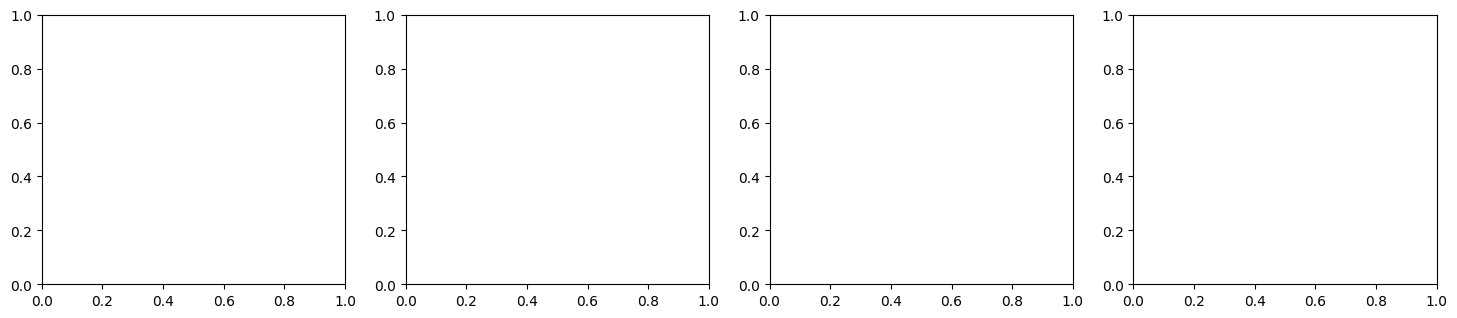

In [46]:
# ISOLATED / ORGANISED

fig, axs = plt.subplots(1,4, figsize=(18, 3.5))

params = dict()

x = ds_good.total_CMT
y_vars = [ds_good.total_cloud_area, ds_good.total_thick_area.sel(threshold=0.25),
          ds_good.total_thick_area.sel(threshold=1), ds_good.total_thick_area.sel(threshold=2.5), ]

colors = ['darkgreen', 'darkblue']
for i, y in enumerate(y_vars):
    ax = axs[i]

    for j, name in enumerate(('isolated','organised')):
        is_isolated = ds_good.category == 'isolated'
        _x, _y = x[is_isolated==j], y[is_isolated==j]

        _, _, xline, yline, result = helpers.evaluate_predictions(_x, _y)
        p_text = r"$p < 0.001$" if result.pvalue < 0.001 else rf"$p = {result.pvalue:.3f}$"
        label = rf"{name}: $r = {result.rvalue:.2f}$ ({p_text})"

        ax.scatter(_x, _y, s=18, alpha=0.3, edgecolors="none", fc=colors[j])
        ax.plot(xline, yline, linewidth=1.5, c=colors[j], label=label)
            
    # axes
    ax.legend(loc='upper left')
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=3, width=0.8)

    ax.set_xlabel("Total $M_c$ [kg]")
    ax.set_ylabel("Area [m$^2$]")

    title = (
        rf"$\mathbf{{({letters[i]})}}$ Overall area"
        if i == 0
        else rf"$\mathbf{{({letters[i]})}}$ Area where IWP > {y.threshold.values:.2f} kg m$^{{-2}}$"
    )
    ax.set_title(title, loc='left')

fig.savefig(extra_figs / 'figure02_isolated_vs_organised.jpg', bbox_inches='tight', dpi=dpi)

In [47]:
# FUNC OF ABH

fig, axs = plt.subplots(1,4, figsize=(18, 3.5))

params = dict()

x = ds_good.total_CMT
y_vars = [ds.total_cloud_area, ds.total_thick_area.sel(threshold=0.25),
          ds.total_thick_area.sel(threshold=1), ds.total_thick_area.sel(threshold=2.5), ]

c_vars = ds.ABH.quantile([0, 0.25, 0.5, 0.75, 1]).rename({"quantile":"pi"})
cmap = plt.get_cmap('Greys')

for i, y in enumerate(y_vars):
    ax = axs[i]

    for j, name in enumerate(c_vars.pi.values):
        current_case = c_vars.sel(pi=name)
        c = cmap(j/5+.1)
        _x, _y = x.sel(system=current_case.system), y.sel(system=current_case.system)

        _, _, xline, yline, result = helpers.evaluate_predictions(_x, _y)
        p_text = r"$p < 0.001$" if result.pvalue < 0.001 else rf"$p = {result.pvalue:.3f}$"
        label = rf"ABH {name}: $r = {result.rvalue:.2f}$ ({p_text})"

        ax.scatter(_x, _y, s=18, alpha=0.3, edgecolors="none", fc=c)
        ax.plot(xline, yline, linewidth=1.5, c=c, label=label)
            
    # axes
    ax.legend(loc='upper left')
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=3, width=0.8)

    ax.set_xlabel("Total $M_c$ [kg]")
    ax.set_ylabel("Area [m$^2$]")

    title = (
        rf"$\mathbf{{({letters[i]})}}$ Overall area"
        if i == 0
        else rf"$\mathbf{{({letters[i]})}}$ Area where IWP > {y.threshold.values:.2f} kg m$^{{-2}}$"
    )
    ax.set_title(title, loc='left')

fig.savefig(extra_figs / 'figure02_by_abh.jpg', bbox_inches='tight', dpi=dpi)

<xarray.Dataset> Size: 204MB
Dimensions:           (system: 4335, threshold: 13, lbins: 99, phase: 5,
                       interp_time: 41)
Coordinates:
  * system            (system) int64 35kB 14669 10718 39920 ... 11546 4146 22226
    lat               (system) float64 35kB 1.9 12.3 5.5 -2.0 ... -8.6 -3.6 2.0
    lon               (system) float64 35kB 15.7 -83.0 120.7 ... 88.4 75.2 4.1
    level_full        (system) int32 17kB 64 58 62 63 64 59 ... 62 64 65 58 63
  * threshold         (threshold) float64 104B 0.01 0.025 0.05 ... 5.0 7.5 10.0
  * lbins             (lbins) float64 792B 0.001 0.001123 ... 79.25 89.02
  * interp_time       (interp_time) float64 328B 0.0 0.025 0.05 ... 0.975 1.0
  * phase             (phase) <U10 200B 'developing' 'mature' ... 'overall'
Data variables: (12/33)
    lifetime          (system) float64 35kB 2.0 3.75 1.75 5.0 ... 1.75 3.75 5.25
    ocean_fraction    (system) float32 17kB 0.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    category          (system) object 35kB 'isolated' 'isolated' ... 'isolated'
    total_thick_area  (system, threshold) float64 451kB 3.146e+10 ... 0.0
    total_cloud_area  (system) float64 35kB 2.045e+10 7.829e+10 ... 1.565e+11
    total_CMT         (system) float64 35kB 2.535e+12 4.164e+12 ... 4.667e+12
    ...                ...
    anvil_div_max     (phase, system, interp_time) float64 7MB nan ... 0.0001996
    anvil_depth_mu    (phase, system, interp_time) float64 7MB 2.104e+03 ... ...
    anvil_rho         (phase, system, interp_time) float64 7MB 0.5279 ... 0.465
    t_max_depth       (system) float64 35kB 0.15 0.15 0.0 0.2 ... 0.0 0.0 0.15
    t_max_area        (system) float64 35kB 1.0 0.5 0.825 ... 0.675 0.425 0.55
    lifestages_valid  (system) float64 35kB 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0

#### EXTENDED FIGURE 3

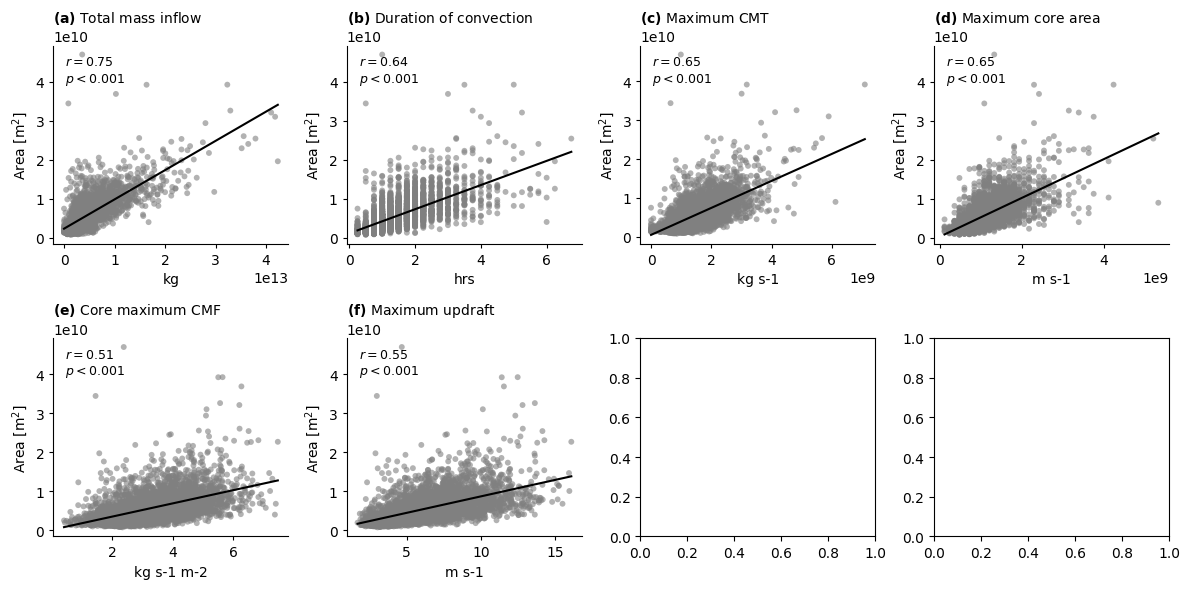

In [59]:
# OVERALL AREA

fig, axs = plt.subplots(2,4, figsize=(12, 6), layout='tight')

params = dict()

y = ds.cloud_area.max(('phase','interp_time'))
x_vars = [ds.total_CMT, ds.conv_lifetime, ds.max_CMT, ds.max_Ac, ds.max_CMF_ABH, ds.max_w, ]


for i, x in enumerate(x_vars):
    ax = axs.flat[i]

    _, _, xline, yline, result = helpers.evaluate_predictions(x, y)
    ax.scatter(x, y, s=18, alpha=0.6, edgecolors="none", fc='grey')
    ax.plot(xline, yline, linewidth=1.5, c='k')
    p_text = r"$p < 0.001$" if result.pvalue < 0.001 else rf"$p = {result.pvalue:.3f}$"
    label = rf"$r = {result.rvalue:.2f}$" + "\n" + p_text #+ "\n" rf"slope = {result.slope:.2f}"
    ax.text(0.05, 0.95, label, transform=ax.transAxes, ha="left", va="top", fontsize=9)

    # axes
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=3, width=0.8)

    ax.set_xlabel(x.attrs['units'])
    ax.set_ylabel("Area [m$^2$]")

    title = rf"$\mathbf{{({letters[i]})}}$ {x.attrs['long_name']}"
    ax.set_title(title, loc='left', fontsize=10)

fig.savefig(extra_figs / 'figure03_area_scatter_plot.jpg', bbox_inches='tight', dpi=dpi)

In [60]:
ds

<xarray.Dataset> Size: 204MB
Dimensions:           (system: 4335, threshold: 13, lbins: 99, phase: 5,
                       interp_time: 41)
Coordinates:
  * system            (system) int64 35kB 14669 10718 39920 ... 11546 4146 22226
    lat               (system) float64 35kB 1.9 12.3 5.5 -2.0 ... -8.6 -3.6 2.0
    lon               (system) float64 35kB 15.7 -83.0 120.7 ... 88.4 75.2 4.1
    level_full        (system) int32 17kB 64 58 62 63 64 59 ... 62 64 65 58 63
  * threshold         (threshold) float64 104B 0.01 0.025 0.05 ... 5.0 7.5 10.0
  * lbins             (lbins) float64 792B 0.001 0.001123 ... 79.25 89.02
  * interp_time       (interp_time) float64 328B 0.0 0.025 0.05 ... 0.975 1.0
  * phase             (phase) <U10 200B 'developing' 'mature' ... 'overall'
Data variables: (12/33)
    lifetime          (system) float64 35kB 2.0 3.75 1.75 5.0 ... 1.75 3.75 5.25
    ocean_fraction    (system) float32 17kB 0.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    category          (system) object 35kB 'isolated' 'isolated' ... 'isolated'
    total_thick_area  (system, threshold) float64 451kB 3.146e+10 ... 0.0
    total_cloud_area  (system) float64 35kB 2.045e+10 7.829e+10 ... 1.565e+11
    total_CMT         (system) float64 35kB 2.535e+12 4.164e+12 ... 4.667e+12
    ...                ...
    anvil_div_max     (phase, system, interp_time) float64 7MB nan ... 0.0001996
    anvil_depth_mu    (phase, system, interp_time) float64 7MB 2.104e+03 ... ...
    anvil_rho         (phase, system, interp_time) float64 7MB 0.5279 ... 0.465
    t_max_depth       (system) float64 35kB 0.15 0.15 0.0 0.2 ... 0.0 0.0 0.15
    t_max_area        (system) float64 35kB 1.0 0.5 0.825 ... 0.675 0.425 0.55
    lifestages_valid  (system) float64 35kB 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0

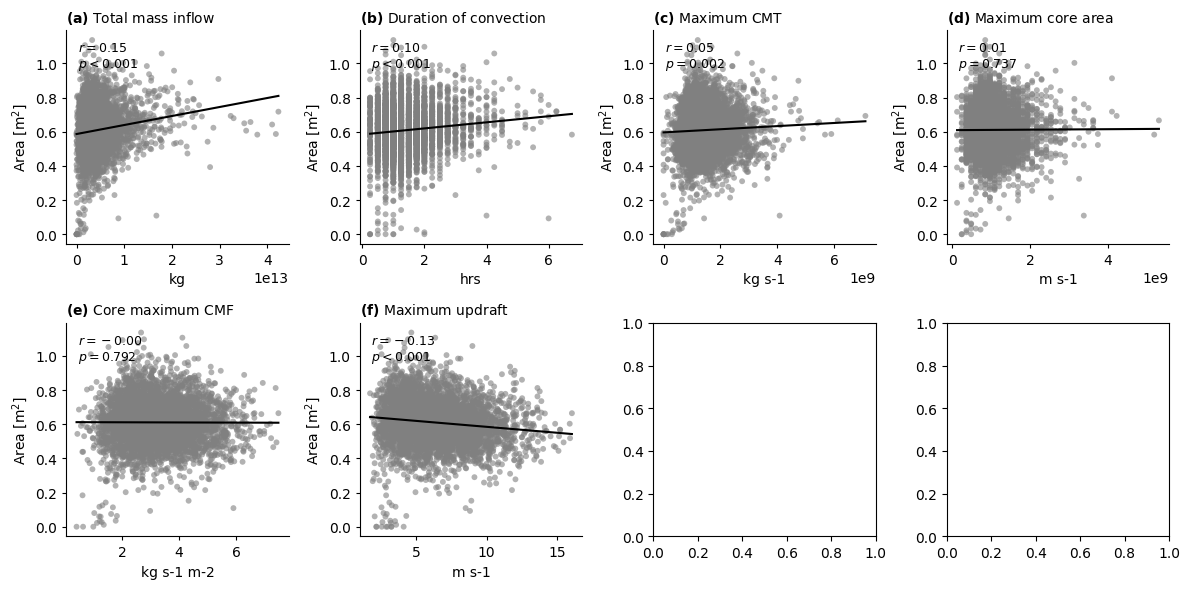

In [64]:
# THICK FRACTION

fig, axs = plt.subplots(2,4, figsize=(12, 6), layout='tight')

params = dict()

y = ds.total_thick_area.sel(threshold=0.25) / ds.total_cloud_area
x_vars = [ds.total_CMT, ds.conv_lifetime, ds.max_CMT, ds.max_Ac, ds.max_CMF_ABH, ds.max_w, ]

for i, x in enumerate(x_vars):
    ax = axs.flat[i]

    _, _, xline, yline, result = helpers.evaluate_predictions(x, y)
    ax.scatter(x, y, s=18, alpha=0.6, edgecolors="none", fc='grey')
    ax.plot(xline, yline, linewidth=1.5, c='k')
    p_text = r"$p < 0.001$" if result.pvalue < 0.001 else rf"$p = {result.pvalue:.3f}$"
    label = rf"$r = {result.rvalue:.2f}$" + "\n" + p_text #+ "\n" rf"slope = {result.slope:.2f}"
    ax.text(0.05, 0.95, label, transform=ax.transAxes, ha="left", va="top", fontsize=9)

    # axes
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=3, width=0.8)

    ax.set_xlabel(x.attrs['units'])
    ax.set_ylabel("Area [m$^2$]")

    title = rf"$\mathbf{{({letters[i]})}}$ {x.attrs['long_name']}"
    ax.set_title(title, loc='left', fontsize=10)

fig.savefig(extra_figs / 'figure03_thick50_scatter_plot.jpg', bbox_inches='tight', dpi=dpi)

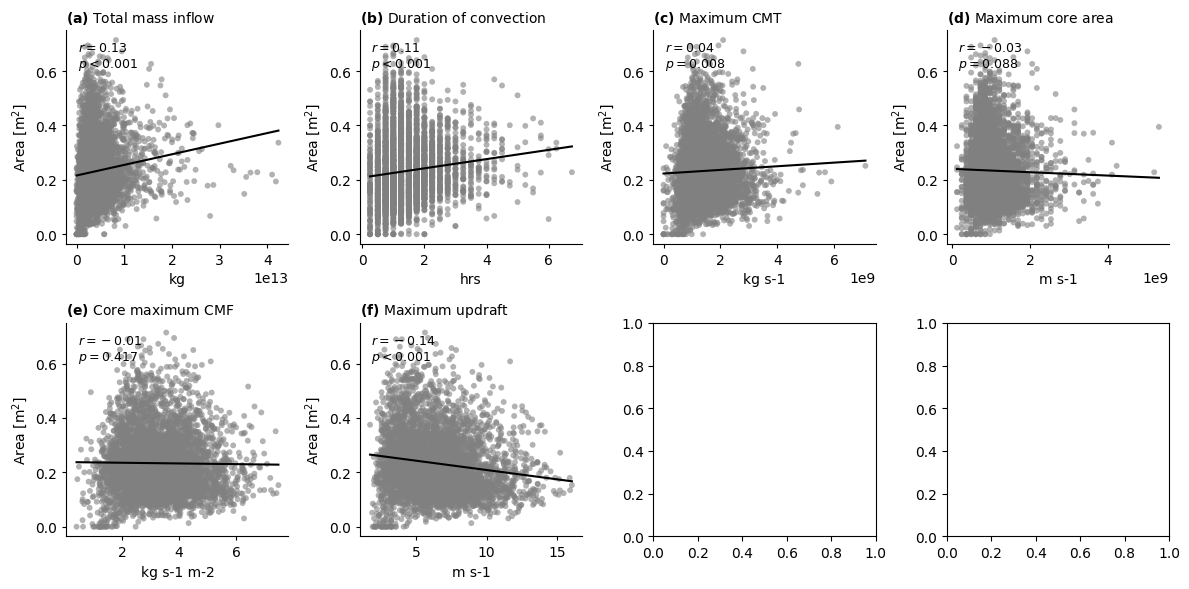

In [61]:
# THICK FRACTION

fig, axs = plt.subplots(2,4, figsize=(12, 6), layout='tight')

params = dict()

y = ds.total_thick_area.sel(threshold=1) / ds.total_cloud_area
x_vars = [ds.total_CMT, ds.conv_lifetime, ds.max_CMT, ds.max_Ac, ds.max_CMF_ABH, ds.max_w, ]

for i, x in enumerate(x_vars):
    ax = axs.flat[i]

    _, _, xline, yline, result = helpers.evaluate_predictions(x, y)
    ax.scatter(x, y, s=18, alpha=0.6, edgecolors="none", fc='grey')
    ax.plot(xline, yline, linewidth=1.5, c='k')
    p_text = r"$p < 0.001$" if result.pvalue < 0.001 else rf"$p = {result.pvalue:.3f}$"
    label = rf"$r = {result.rvalue:.2f}$" + "\n" + p_text #+ "\n" rf"slope = {result.slope:.2f}"
    ax.text(0.05, 0.95, label, transform=ax.transAxes, ha="left", va="top", fontsize=9)

    # axes
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=3, width=0.8)

    ax.set_xlabel(x.attrs['units'])
    ax.set_ylabel("Area [m$^2$]")

    title = rf"$\mathbf{{({letters[i]})}}$ {x.attrs['long_name']}"
    ax.set_title(title, loc='left', fontsize=10)

fig.savefig(extra_figs / 'figure03_thick80_scatter_plot.jpg', bbox_inches='tight', dpi=dpi)

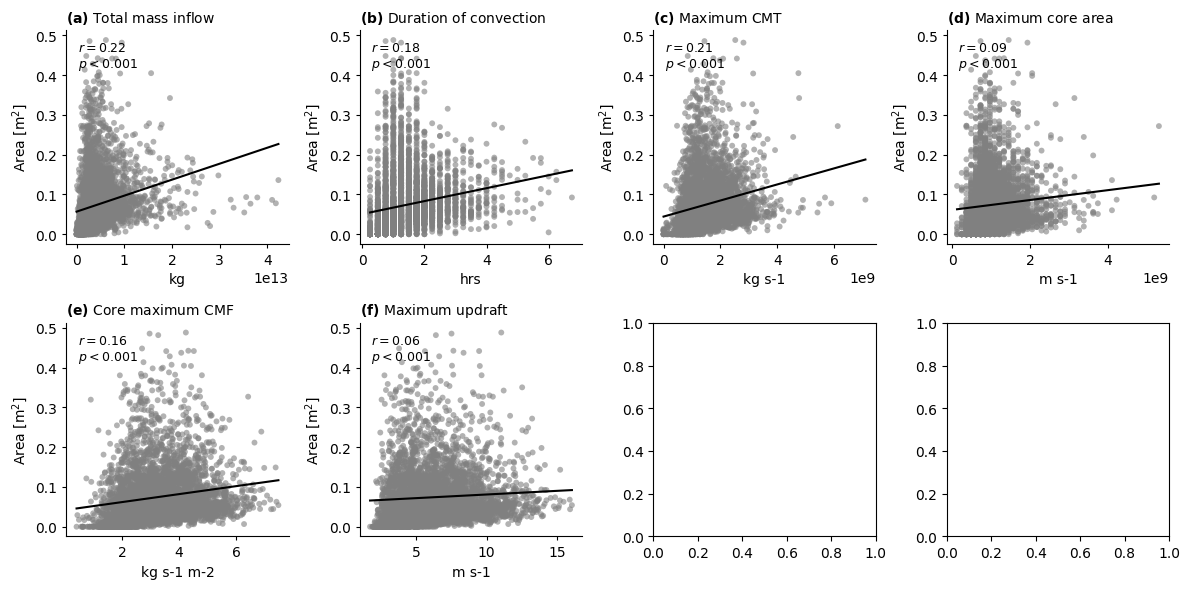

In [63]:
# THICK FRACTION

fig, axs = plt.subplots(2,4, figsize=(12, 6), layout='tight')

params = dict()

y = ds.total_thick_area.sel(threshold=2.5) / ds.total_cloud_area
x_vars = [ds.total_CMT, ds.conv_lifetime, ds.max_CMT, ds.max_Ac, ds.max_CMF_ABH, ds.max_w, ]

for i, x in enumerate(x_vars):
    ax = axs.flat[i]

    _, _, xline, yline, result = helpers.evaluate_predictions(x, y)
    ax.scatter(x, y, s=18, alpha=0.6, edgecolors="none", fc='grey')
    ax.plot(xline, yline, linewidth=1.5, c='k')
    p_text = r"$p < 0.001$" if result.pvalue < 0.001 else rf"$p = {result.pvalue:.3f}$"
    label = rf"$r = {result.rvalue:.2f}$" + "\n" + p_text #+ "\n" rf"slope = {result.slope:.2f}"
    ax.text(0.05, 0.95, label, transform=ax.transAxes, ha="left", va="top", fontsize=9)

    # axes
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=3, width=0.8)

    ax.set_xlabel(x.attrs['units'])
    ax.set_ylabel("Area [m$^2$]")

    title = rf"$\mathbf{{({letters[i]})}}$ {x.attrs['long_name']}"
    ax.set_title(title, loc='left', fontsize=10)

fig.savefig(extra_figs / 'figure03_thick95_scatter_plot.jpg', bbox_inches='tight', dpi=dpi)